In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

In [6]:
DATA_PATH = Path(
    "../data/processed/daily_room_demand.csv"
)

df = pd.read_csv(DATA_PATH)

df["occupied_date"] = pd.to_datetime(
    df["occupied_date"]
)

df = df.sort_values(
    ["hotel", "room_category", "occupied_date"]
).reset_index(drop=True)

print("Shape:", df.shape)

display(df.head())

Shape: (13702, 4)


,occupied_date,hotel,room_category,occupied_room_nights
0,2015-07-01,City Hotel,A,6.0
1,2015-07-02,City Hotel,A,7.0
2,2015-07-03,City Hotel,A,8.0
3,2015-07-04,City Hotel,A,12.0
4,2015-07-05,City Hotel,A,7.0


In [11]:
df["day_of_week"] = (
    df["occupied_date"].dt.day_of_week
)

display(
    df[
        ["occupied_date", "day_of_week"]
    ].head(10)
)


,occupied_date,day_of_week
0,2015-07-01,2
1,2015-07-02,3
2,2015-07-03,4
3,2015-07-04,5
4,2015-07-05,6
5,2015-07-06,0
6,2015-07-07,1
7,2015-07-08,2
8,2015-07-09,3
9,2015-07-10,4


In [13]:
df["day"] = df["occupied_date"].dt.day

df["month"] = df["occupied_date"].dt.month

df["year"] = df["occupied_date"].dt.year

df["quarter"] = df["occupied_date"].dt.quarter

df["day_of_year"] = (
    df["occupied_date"].dt.day_of_year
)

In [14]:
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)


In [16]:
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"


df["season"] = df["month"].apply(
    get_season
)

In [17]:
GROUP_COLS = [
    "hotel",
    "room_category"
]

TARGET = "occupied_room_nights"

df = df.sort_values(
    GROUP_COLS + ["occupied_date"]
).copy()

In [18]:
for lag in [1, 7, 14, 28]:

    df[f"lag_{lag}"] = (
        df.groupby(GROUP_COLS)[TARGET]
        .shift(lag)
    )

In [19]:
display(
    df[
        GROUP_COLS
        + [
            "occupied_date",
            TARGET,
            "lag_1",
            "lag_7",
            "lag_14",
            "lag_28"
        ]
    ].head(40)
)

,hotel,room_category,occupied_date,occupied_room_nights,lag_1,lag_7,lag_14,lag_28
0,City Hotel,A,2015-07-01,6.0,NaN,NaN,NaN,NaN
1,City Hotel,A,2015-07-02,7.0,6.0,NaN,NaN,NaN
2,City Hotel,A,2015-07-03,8.0,7.0,NaN,NaN,NaN
3,City Hotel,A,2015-07-04,12.0,8.0,NaN,NaN,NaN
4,City Hotel,A,2015-07-05,7.0,12.0,NaN,NaN,NaN
5,City Hotel,A,2015-07-06,6.0,7.0,NaN,NaN,NaN
6,City Hotel,A,2015-07-07,7.0,6.0,NaN,NaN,NaN
7,City Hotel,A,2015-07-08,10.0,7.0,6.0,NaN,NaN
8,City Hotel,A,2015-07-09,10.0,10.0,7.0,NaN,NaN
9,City Hotel,A,2015-07-10,6.0,10.0,8.0,NaN,NaN


In [23]:
df["rolling_std_7"] = (
    df.groupby(GROUP_COLS)[TARGET]
    .transform(
        lambda x: x.shift(1).rolling(
            window=7,
            min_periods=7
        ).std()
    )
)

In [24]:
for col in [
    "hotel",
    "room_category",
    "season"
]:

    print(f"\n{col}")

    print(df[col].value_counts())


hotel
hotel
Resort Hotel    7254
City Hotel      6448
Name: count, dtype: int64

room_category
room_category
A    1612
B    1612
C    1612
D    1612
E    1612
F    1612
G    1612
K     806
H     806
I     806
Name: count, dtype: int64

season
season
Summer    4182
Autumn    3315
Spring    3128
Winter    3077
Name: count, dtype: int64


In [25]:
feature_columns = [
    "day_of_week",
    "day",
    "month",
    "year",
    "quarter",
    "day_of_year",
    "is_weekend",
    "season",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_7"
]

display(
    df[feature_columns].isnull().sum()
)

day_of_week          0
day                  0
month                0
year                 0
quarter              0
day_of_year          0
is_weekend           0
season               0
lag_1               17
lag_7              119
lag_14             238
lag_28             476
rolling_mean_7     119
rolling_mean_14    238
rolling_mean_28    476
rolling_std_7      119
dtype: int64

In [26]:
df_model = df.dropna(
    subset=feature_columns
).copy()

print("Before:", df.shape)

print("After:", df_model.shape)

Before: (13702, 20)
After: (13226, 20)


In [29]:
unique_dates = np.sort(
    df_model["occupied_date"].unique()
)

n_dates = len(unique_dates)

train_end = int(n_dates * 0.70)

val_end = int(n_dates * 0.85)

train_dates = unique_dates[:train_end]

val_dates = unique_dates[train_end:val_end]

test_dates = unique_dates[val_end:]

train_df = df_model[
    df_model["occupied_date"].isin(train_dates)
].copy()

val_df = df_model[
    df_model["occupied_date"].isin(val_dates)
].copy()

test_df = df_model[
    df_model["occupied_date"].isin(test_dates)
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nDate boundaries:")

print("Train:", train_dates[0], "to", train_dates[-1])

print("Validation:", val_dates[0], "to", val_dates[-1])

print("Test:", test_dates[0], "to", test_dates[-1])

Train: (9248, 20)
Validation: (1989, 20)
Test: (1989, 20)

Date boundaries:
Train: 2015-07-29T00:00:00.000000 to 2017-01-22T00:00:00.000000
Validation: 2017-01-23T00:00:00.000000 to 2017-05-19T00:00:00.000000
Test: 2017-05-20T00:00:00.000000 to 2017-09-13T00:00:00.000000


In [30]:
assert train_df["occupied_date"].max() < (
    val_df["occupied_date"].min()
)

assert val_df["occupied_date"].max() < (
    test_df["occupied_date"].min()
)

print("Chronological split verified!")

Chronological split verified!


In [31]:
FEATURES = [
    "hotel",
    "room_category",
    "day_of_week",
    "day",
    "month",
    "year",
    "quarter",
    "day_of_year",
    "is_weekend",
    "season",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_7"
]

TARGET = "occupied_room_nights"

In [34]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

display(X_train.head())

display(y_train.head())

X_train: (9248, 18)
y_train: (9248,)
X_val: (1989, 18)
y_val: (1989,)
X_test: (1989, 18)
y_test: (1989,)


,hotel,room_category,day_of_week,day,month,year,quarter,day_of_year,is_weekend,season,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7
28,City Hotel,A,2,29,7,2015,3,210,0,Summer,17.0,9.0,6.0,6.0,13.571429,11.571429,10.035714,5.912054
29,City Hotel,A,3,30,7,2015,3,211,0,Summer,14.0,13.0,6.0,7.0,14.285714,12.142857,10.321429,5.559205
30,City Hotel,A,4,31,7,2015,3,212,0,Summer,10.0,4.0,4.0,8.0,13.857143,12.428571,10.428571,5.785861
31,City Hotel,A,5,1,8,2015,3,213,1,Summer,11.0,20.0,17.0,12.0,14.857143,12.928571,10.535714,4.180453
32,City Hotel,A,6,2,8,2015,3,214,1,Summer,11.0,12.0,14.0,7.0,13.571429,12.500000,10.500000,3.690399


28    14.0
29    10.0
30    11.0
31    11.0
32    11.0
Name: occupied_room_nights, dtype: float64

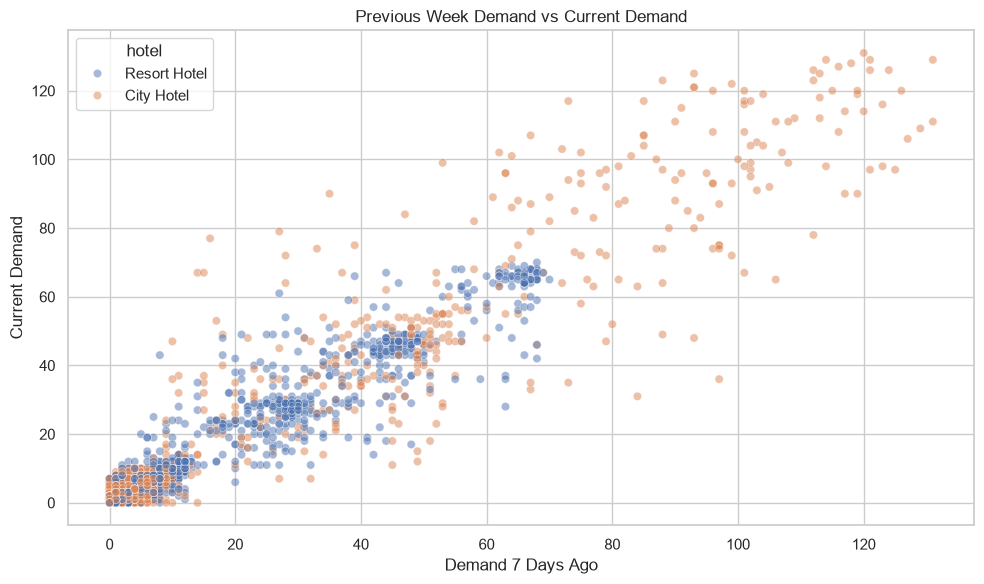

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df.sample(
        min(3000, len(train_df)),
        random_state=42
    ),
    x="lag_7",
    y=TARGET,
    hue="hotel",
    alpha=0.5
)

plt.title("Previous Week Demand vs Current Demand")
plt.xlabel("Demand 7 Days Ago")
plt.ylabel("Current Demand")

plt.tight_layout()
plt.show()

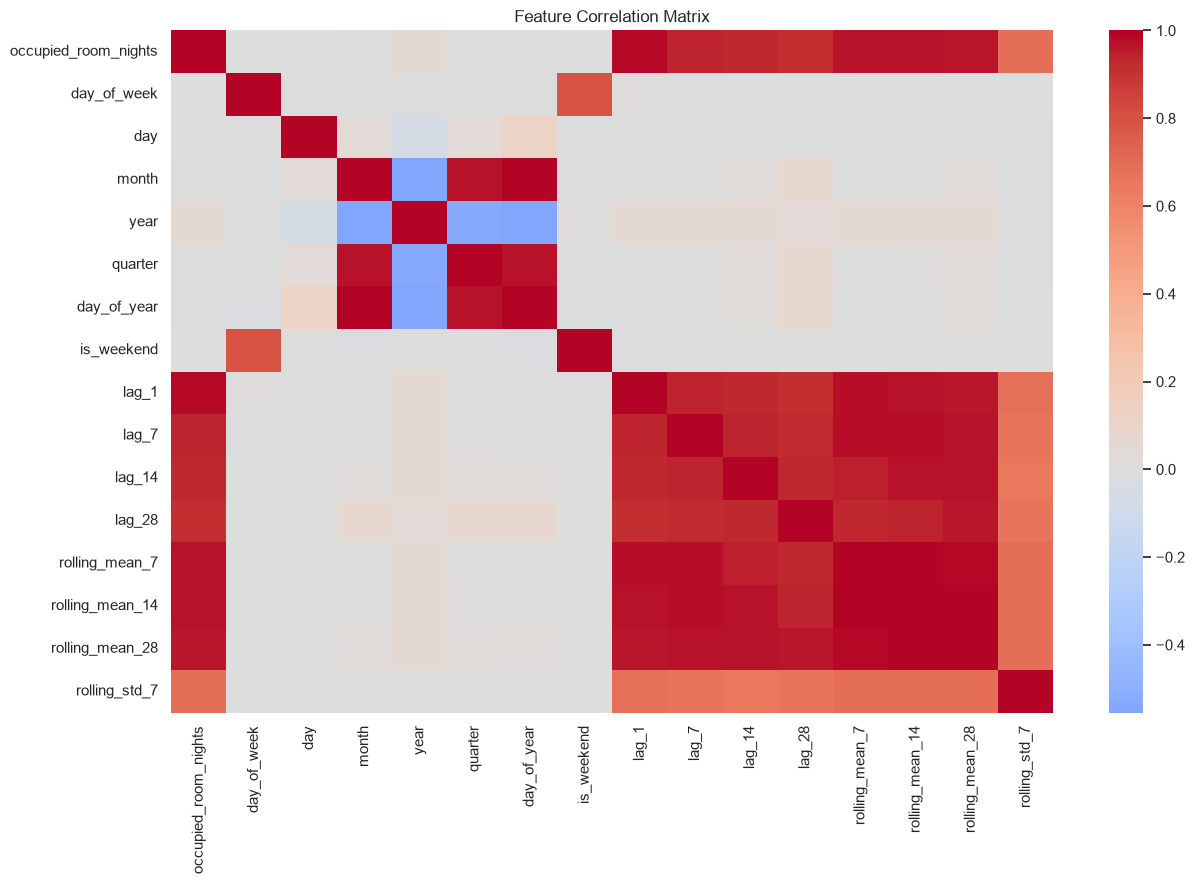

In [36]:
numeric_features = train_df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_features.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [37]:
OUTPUT_DIR = Path("../data/processed")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df_model.to_csv(
    OUTPUT_DIR / "modeling_dataset.csv",
    index=False
)

In [38]:
train_df.to_csv(
    OUTPUT_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / "test.csv",
    index=False
)